# DSB2018 preprocessing for FCIS

这个 notebook 做两件事：

1. 从 DSB2018 `origin` 目录和 `train_val_list.txt / test_list.txt` 生成 split 后的数据：
   - `{DATA_ROOT}/{split}/images/*.png`
   - `{DATA_ROOT}/{split}/masks/{slide_id}.npy`

2. 以前面生成的 image 和 instance mask `.npy` 为输入，继续生成 FCIS 训练需要的数据结构：
   - `data256/hovernet/{split}/*.npy`
   - `data256/mmseg/images/{split}/*.png`
   - `data256/mmseg/masks/{split}/*.png`
   - `data256/mmseg/insts/{split}/*.npy`
   - `data256/mmseg/fcis_inst/{split}/*.png`  四色编码 label map
   - `data256/mmseg/fcis_inst/{split}/*.npy`  instance label
   - `data256/mmseg/adjacency/{split}/*.yaml`
   - `data256/mmseg/{split}.txt`

默认会重新生成 split images/masks 和 `data256` 结果。如果你前面已经生成好了 image/mask，可以把 `RUN_PREPARE_SPLIT_DATA = False`。

In [1]:
from pathlib import Path
import os
import shutil
import random
import sys

import numpy as np
from PIL import Image
from tqdm import tqdm

# Optional dependencies used by later stages
import cv2
import yaml
import networkx as nx
from skimage import measure
import matplotlib.pyplot as plt
from matplotlib import colors

# =========================
# Global config
# =========================

DATA_ROOT = Path('/data5/zhangye/FCIS/data/DSB2018')
ORIGIN_ROOT = DATA_ROOT / 'origin'

TRAIN_VAL_LIST = Path('train_val_list.txt')
TEST_LIST = Path('test_list.txt')

SPLITS = ['train', 'val', 'test']

# If you have already generated DATA_ROOT/{split}/images and DATA_ROOT/{split}/masks/*.npy,
# set this to False and directly run the FCIS preprocessing stages.
RUN_PREPARE_SPLIT_DATA = True

# Main FCIS preprocessing switch.
RUN_BUILD_FCIS_DATA = True

# Patch setting used by the original notebook.
PATCH_SIZE = 256
STEP = 256

# Relabel instance ids in each 256x256 patch to 1..M.
# This is usually cleaner for patch-level instance training.
RELABEL_EACH_PATCH = True

# Keep patches without nuclei. The original notebook keeps all grid patches.
KEEP_EMPTY_PATCHES = True

# Whether to clear old data256 outputs before generating new files.
RESET_DATA256_OUTPUT = True

# Output roots
DATA256_ROOT = DATA_ROOT / 'data256'
HOVERNET_ROOT = DATA256_ROOT / 'hovernet'
MMSEG_ROOT = DATA256_ROOT / 'mmseg'

print('DATA_ROOT =', DATA_ROOT)
print('ORIGIN_ROOT =', ORIGIN_ROOT)
print('MMSEG_ROOT =', MMSEG_ROOT)

DATA_ROOT = /data5/zhangye/FCIS/data/DSB2018
ORIGIN_ROOT = /data5/zhangye/FCIS/data/DSB2018/origin
MMSEG_ROOT = /data5/zhangye/FCIS/data/DSB2018/data256/mmseg


## 1. Generate split images and merged instance `.npy` masks

这一部分整合了你前面的代码。每个样本原始 mask 目录里有很多单细胞 PNG mask，本节会把它们合成一个 instance label `.npy`：背景为 0，每个细胞依次编码为 1 到 N。

In [2]:
def normalize_image_name(name: str) -> str:
    """Convert list filename to png filename."""
    name = Path(str(name).strip()).name
    name = name.replace('.tiff', '.png').replace('.tif', '.png')
    return name


def get_slide_id_from_image_name(image_name: str) -> str:
    return Path(image_name).stem


def merge_single_cell_masks_to_instance_npy(mask_dir, save_path, expected_shape=None):
    """
    Merge many single-cell binary PNG masks into one instance label npy.

    Parameters
    ----------
    mask_dir : str or Path
        Directory containing one PNG per cell.
    save_path : str or Path
        Output .npy path.
    expected_shape : tuple or None
        Optional expected (H, W), usually from the image shape.

    Returns
    -------
    int
        Number of non-empty instance masks merged.
    """
    mask_dir = Path(mask_dir)
    save_path = Path(save_path)
    save_path.parent.mkdir(parents=True, exist_ok=True)

    mask_files = sorted([
        p for p in mask_dir.iterdir()
        if p.is_file() and p.suffix.lower() in ['.png', '.tif', '.tiff']
    ])

    if len(mask_files) == 0:
        if expected_shape is None:
            raise FileNotFoundError(f'No mask files found in {mask_dir}, and expected_shape is None.')
        instance_mask = np.zeros(expected_shape, dtype=np.uint16)
        np.save(save_path, instance_mask)
        print(f'[Warning] no mask files in {mask_dir}; saved empty mask: {save_path}')
        return 0

    first = np.array(Image.open(mask_files[0]).convert('L'))
    h, w = first.shape

    if expected_shape is not None and (h, w) != tuple(expected_shape):
        raise ValueError(f'Mask shape mismatch in {mask_dir}: first mask {(h, w)}, image {expected_shape}')

    dtype = np.uint16 if len(mask_files) <= np.iinfo(np.uint16).max else np.uint32
    instance_mask = np.zeros((h, w), dtype=dtype)

    instance_id = 1
    overlap_pixels = 0

    for mask_file in mask_files:
        mask = np.array(Image.open(mask_file).convert('L'))

        if mask.shape != (h, w):
            raise ValueError(f'Mask shape mismatch: {mask_file}, got {mask.shape}, expected {(h, w)}')

        binary = mask > 0
        if not np.any(binary):
            continue

        # DSB instance masks should not overlap. If overlap exists, later masks overwrite only
        # the overlapped pixels. We count it for debugging.
        overlap_pixels += int(np.logical_and(binary, instance_mask > 0).sum())
        instance_mask[binary] = instance_id
        instance_id += 1

    np.save(save_path, instance_mask)

    if overlap_pixels > 0:
        print(f'[Warning] {save_path.name}: found {overlap_pixels} overlapped pixels while merging masks.')

    return instance_id - 1


def prepare_one_sample_from_origin(image_name: str, split: str):
    """
    Copy one image from origin and merge its single-cell mask PNGs to one .npy mask.

    Output:
        DATA_ROOT/{split}/images/{image_name}
        DATA_ROOT/{split}/masks/{slide_id}.npy
        DATA_ROOT/{split}/masks/{slide_id}/   # copied original single-cell masks
    """
    image_name = normalize_image_name(image_name)
    slide_id = get_slide_id_from_image_name(image_name)

    src_img = ORIGIN_ROOT / slide_id / 'images' / image_name
    src_mask_dir = ORIGIN_ROOT / slide_id / 'masks'

    dst_img_dir = DATA_ROOT / split / 'images'
    dst_mask_root = DATA_ROOT / split / 'masks'
    dst_mask_png_dir = dst_mask_root / slide_id

    dst_img = dst_img_dir / image_name
    dst_mask_npy = dst_mask_root / f'{slide_id}.npy'

    dst_img_dir.mkdir(parents=True, exist_ok=True)
    dst_mask_root.mkdir(parents=True, exist_ok=True)

    if not src_img.exists():
        raise FileNotFoundError(f'Image not found: {src_img}')
    if not src_mask_dir.exists():
        raise FileNotFoundError(f'Mask directory not found: {src_mask_dir}')

    shutil.copy2(src_img, dst_img)

    # Copy original single-cell mask folder for traceability.
    if dst_mask_png_dir.exists():
        shutil.rmtree(dst_mask_png_dir)
    shutil.copytree(src_mask_dir, dst_mask_png_dir)

    image_arr = np.array(Image.open(dst_img).convert('RGB'))
    expected_shape = image_arr.shape[:2]

    n_inst = merge_single_cell_masks_to_instance_npy(
        mask_dir=dst_mask_png_dir,
        save_path=dst_mask_npy,
        expected_shape=expected_shape,
    )

    return slide_id, n_inst


def prepare_split_data_from_lists():
    """Read train_val_list.txt and test_list.txt, then prepare images and merged masks."""
    counters = {split: 0 for split in SPLITS}
    instance_counters = {split: 0 for split in SPLITS}

    if TRAIN_VAL_LIST.exists():
        with open(TRAIN_VAL_LIST, 'r') as f:
            for line in tqdm(f, desc='Preparing train/val'):
                line = line.strip()
                if not line:
                    continue

                parts = [x.strip() for x in line.split(',')]
                if len(parts) < 2:
                    print(f'[Warning] Skip invalid line in train_val_list: {line}')
                    continue

                image_name = parts[1]
                split = parts[-1]
                if split not in ['train', 'val']:
                    print(f'[Warning] Unknown split `{split}` in line: {line}. Skip.')
                    continue

                _, n_inst = prepare_one_sample_from_origin(image_name, split)
                counters[split] += 1
                instance_counters[split] += n_inst
    else:
        print(f'[Warning] train_val_list not found: {TRAIN_VAL_LIST}')

    if TEST_LIST.exists():
        with open(TEST_LIST, 'r') as f:
            for line in tqdm(f, desc='Preparing test'):
                line = line.strip()
                if not line:
                    continue

                # test_list usually has one filename per line.
                # If it accidentally contains comma-separated fields, use the last filename-looking field.
                parts = [x.strip() for x in line.split(',')]
                image_name = parts[-1]

                _, n_inst = prepare_one_sample_from_origin(image_name, 'test')
                counters['test'] += 1
                instance_counters['test'] += n_inst
    else:
        print(f'[Warning] test_list not found: {TEST_LIST}')

    print('\nDone preparing split data.')
    for split in SPLITS:
        print(f'{split:5s}: {counters[split]} images, {instance_counters[split]} instances')


if RUN_PREPARE_SPLIT_DATA:
    prepare_split_data_from_lists()
else:
    print('Skip split-data generation because RUN_PREPARE_SPLIT_DATA = False')

[Warning] train_val_list not found: train_val_list.txt
[Warning] test_list not found: test_list.txt

Done preparing split data.
train: 0 images, 0 instances
val  : 0 images, 0 instances
test : 0 images, 0 instances


## 2. Split image and instance mask into 256×256 patch `.npy`

输入来自前一步：

```text
DATA_ROOT/{split}/images/*.png
DATA_ROOT/{split}/masks/*.npy
```

输出为原 notebook 的 HoverNet 风格中间文件：

```text
DATA_ROOT/data256/hovernet/{split}/{slide_id}_{patch_id}.npy
```

每个 patch `.npy` 的 shape 是 `256 × 256 × 4`，前三个通道是 RGB image，第 4 个通道是 instance mask。

In [3]:
def reset_dir(path: Path):
    path = Path(path)
    if path.exists():
        shutil.rmtree(path)
    path.mkdir(parents=True, exist_ok=True)


def relabel_instance_mask(mask: np.ndarray) -> np.ndarray:
    """Relabel positive instance ids in a mask to contiguous ids 1..M."""
    mask = np.asarray(mask)
    unique_ids = np.unique(mask)
    unique_ids = unique_ids[unique_ids > 0]

    if len(unique_ids) == 0:
        return np.zeros(mask.shape, dtype=np.uint16)

    dtype = np.uint16 if len(unique_ids) <= np.iinfo(np.uint16).max else np.uint32
    relabeled = np.zeros(mask.shape, dtype=dtype)
    for new_id, old_id in enumerate(unique_ids, start=1):
        relabeled[mask == old_id] = new_id
    return relabeled


def split_and_save_patches(input_image_path, input_mask_path, output_split_dir,
                           image_base_name, patch_size=256, step=256,
                           relabel_each_patch=True, keep_empty=True):
    input_image_path = Path(input_image_path)
    input_mask_path = Path(input_mask_path)
    output_split_dir = Path(output_split_dir)
    output_split_dir.mkdir(parents=True, exist_ok=True)

    image = np.array(Image.open(input_image_path).convert('RGB'), dtype=np.uint8)
    mask = np.load(input_mask_path)

    if mask.ndim != 2:
        raise ValueError(f'Mask should be 2D: {input_mask_path}, got shape={mask.shape}')

    img_h, img_w = image.shape[:2]
    mask_h, mask_w = mask.shape

    if (img_h, img_w) != (mask_h, mask_w):
        raise ValueError(
            f'Dimension mismatch for {input_image_path.name}: image {(img_h, img_w)}, mask {(mask_h, mask_w)}'
        )

    if patch_size > img_h or patch_size > img_w:
        print(f'[Warning] skip {input_image_path.name}: patch_size={patch_size} > image size={(img_h, img_w)}')
        return 0

    patch_count = 0
    saved_count = 0

    for y in range(0, img_h - patch_size + 1, step):
        for x in range(0, img_w - patch_size + 1, step):
            img_patch = image[y:y + patch_size, x:x + patch_size, :]
            mask_patch = mask[y:y + patch_size, x:x + patch_size]

            if relabel_each_patch:
                mask_patch = relabel_instance_mask(mask_patch)

            if (not keep_empty) and np.max(mask_patch) == 0:
                patch_count += 1
                continue

            # Concatenate RGB image and instance mask into H x W x 4.
            # Image channels will be safely converted back to uint8 in the next stage.
            combined_patch = np.concatenate(
                [img_patch.astype(mask_patch.dtype), mask_patch[..., None]], axis=-1
            )

            patch_filename = output_split_dir / f'{image_base_name}_{patch_count:04d}.npy'
            np.save(patch_filename, combined_patch)

            patch_count += 1
            saved_count += 1

    return saved_count


def build_hovernet_patch_npy():
    if RESET_DATA256_OUTPUT:
        reset_dir(HOVERNET_ROOT)
    else:
        HOVERNET_ROOT.mkdir(parents=True, exist_ok=True)

    summary = {}

    for split in SPLITS:
        input_images_dir = DATA_ROOT / split / 'images'
        input_masks_dir = DATA_ROOT / split / 'masks'
        output_split_dir = HOVERNET_ROOT / split
        output_split_dir.mkdir(parents=True, exist_ok=True)

        if not input_images_dir.exists():
            print(f'[Warning] image directory not found, skip {split}: {input_images_dir}')
            continue
        if not input_masks_dir.exists():
            print(f'[Warning] mask directory not found, skip {split}: {input_masks_dir}')
            continue

        image_files = sorted([p for p in input_images_dir.iterdir() if p.is_file() and p.suffix.lower() == '.png'])
        print(f'\n[{split}] found {len(image_files)} images')

        total_patches = 0
        failed = 0

        for image_path in tqdm(image_files, desc=f'Splitting {split}'):
            base_name = image_path.stem
            mask_path = input_masks_dir / f'{base_name}.npy'

            if not mask_path.exists():
                print(f'[Warning] missing mask for {image_path.name}: {mask_path}')
                failed += 1
                continue

            try:
                n = split_and_save_patches(
                    input_image_path=image_path,
                    input_mask_path=mask_path,
                    output_split_dir=output_split_dir,
                    image_base_name=base_name,
                    patch_size=PATCH_SIZE,
                    step=STEP,
                    relabel_each_patch=RELABEL_EACH_PATCH,
                    keep_empty=KEEP_EMPTY_PATCHES,
                )
                total_patches += n
            except Exception as e:
                print(f'[Error] failed to split {image_path}: {e}')
                failed += 1

        summary[split] = {'images': len(image_files), 'patches': total_patches, 'failed': failed}
        print(f'[{split}] patches saved: {total_patches}, failed images: {failed}')

    return summary


if RUN_BUILD_FCIS_DATA:
    hovernet_summary = build_hovernet_patch_npy()
    print('\nHoverNet-style patch summary:', hovernet_summary)
else:
    print('Skip patch generation because RUN_BUILD_FCIS_DATA = False')


[train] found 380 images


Splitting train: 100%|██████████| 380/380 [00:03<00:00, 120.32it/s]


[train] patches saved: 602, failed images: 0

[val] found 67 images


Splitting val: 100%|██████████| 67/67 [00:00<00:00, 121.07it/s]


[val] patches saved: 109, failed images: 0

[test] found 50 images


Splitting test: 100%|██████████| 50/50 [00:00<00:00, 106.44it/s]

[test] patches saved: 89, failed images: 0

HoverNet-style patch summary: {'train': {'images': 380, 'patches': 602, 'failed': 0}, 'val': {'images': 67, 'patches': 109, 'failed': 0}, 'test': {'images': 50, 'patches': 89, 'failed': 0}}


## 3. Convert patch `.npy` to mmseg-style image / binary mask / instance label

输出结构：

```text
data256/mmseg/images/{split}/*.png   # RGB patch image
data256/mmseg/masks/{split}/*.png    # binary foreground mask, values 0/1
data256/mmseg/insts/{split}/*.npy    # instance label mask
```

In [4]:
def process_single_combined_patch_npy(npy_filepath, output_img_dir, output_mask_dir, output_inst_dir):
    npy_filepath = Path(npy_filepath)
    output_img_dir = Path(output_img_dir)
    output_mask_dir = Path(output_mask_dir)
    output_inst_dir = Path(output_inst_dir)

    data = np.load(npy_filepath)

    if data.ndim != 3 or data.shape[-1] < 4:
        raise ValueError(f'Expected H x W x 4 array, got {data.shape}: {npy_filepath}')

    image_data = data[..., :3].astype(np.uint8)
    instance_data = data[..., 3]

    if RELABEL_EACH_PATCH:
        instance_data = relabel_instance_mask(instance_data)

    binary_mask = (instance_data > 0).astype(np.uint8)

    base_name = npy_filepath.stem

    Image.fromarray(image_data).save(output_img_dir / f'{base_name}.png')
    Image.fromarray(binary_mask).save(output_mask_dir / f'{base_name}.png')
    np.save(output_inst_dir / f'{base_name}.npy', instance_data)


def build_mmseg_from_hovernet_patches():
    if RESET_DATA256_OUTPUT:
        # Do not remove HOVERNET_ROOT here because it was generated in the previous step.
        for sub in ['images', 'masks', 'insts', 'fcis_inst', 'adjacency']:
            path = MMSEG_ROOT / sub
            if path.exists():
                shutil.rmtree(path)
    MMSEG_ROOT.mkdir(parents=True, exist_ok=True)

    summary = {}

    for split in SPLITS:
        source_split_path = HOVERNET_ROOT / split
        output_img_split_dir = MMSEG_ROOT / 'images' / split
        output_mask_split_dir = MMSEG_ROOT / 'masks' / split
        output_inst_split_dir = MMSEG_ROOT / 'insts' / split

        output_img_split_dir.mkdir(parents=True, exist_ok=True)
        output_mask_split_dir.mkdir(parents=True, exist_ok=True)
        output_inst_split_dir.mkdir(parents=True, exist_ok=True)

        if not source_split_path.exists():
            print(f'[Warning] source patch dir not found, skip {split}: {source_split_path}')
            continue

        npy_files = sorted([p for p in source_split_path.iterdir() if p.is_file() and p.suffix == '.npy'])
        print(f'\n[{split}] converting {len(npy_files)} patch npy files to mmseg format')

        failed = 0
        for npy_file in tqdm(npy_files, desc=f'Converting {split}'):
            try:
                process_single_combined_patch_npy(
                    npy_filepath=npy_file,
                    output_img_dir=output_img_split_dir,
                    output_mask_dir=output_mask_split_dir,
                    output_inst_dir=output_inst_split_dir,
                )
            except Exception as e:
                print(f'[Error] failed to convert {npy_file}: {e}')
                failed += 1

        summary[split] = {'patch_npy': len(npy_files), 'failed': failed}
        print(f'[{split}] converted: {len(npy_files) - failed}, failed: {failed}')

    return summary


if RUN_BUILD_FCIS_DATA:
    mmseg_summary = build_mmseg_from_hovernet_patches()
    print('\nMMSEG summary:', mmseg_summary)
else:
    print('Skip mmseg generation because RUN_BUILD_FCIS_DATA = False')


[train] converting 602 patch npy files to mmseg format


Converting train: 100%|██████████| 602/602 [00:12<00:00, 48.18it/s]


[train] converted: 602, failed: 0

[val] converting 109 patch npy files to mmseg format


Converting val: 100%|██████████| 109/109 [00:02<00:00, 50.82it/s]


[val] converted: 109, failed: 0

[test] converting 89 patch npy files to mmseg format


Converting test: 100%|██████████| 89/89 [00:01<00:00, 47.09it/s]

[test] converted: 89, failed: 0

MMSEG summary: {'train': {'patch_npy': 602, 'failed': 0}, 'val': {'patch_npy': 109, 'failed': 0}, 'test': {'patch_npy': 89, 'failed': 0}}


## 4. Generate FCIS four-color encoding

从 `mmseg/insts/{split}/*.npy` 读取 instance mask，建立细胞邻接图，然后用 greedy graph coloring 生成 1–4 的四色 label map。

输出：

```text
data256/mmseg/fcis_inst/{split}/*.png         # 四色编码，像素值 0/1/2/3/4
data256/mmseg/fcis_inst/{split}/*.npy         # 原始 instance label，便于训练/检查
data256/mmseg/fcis_inst/{split}/visual/*.png  # 可视化图
```

In [5]:
FOUR_COLORS = ['black', 'red', 'green', 'blue', 'yellow']
ADJACENCY_RADIUS = 5


def create_adjacency_graph(label_img: np.ndarray, radius: int = 5):
    """
    Create adjacency graph based on labeled instance image.
    Two instances are connected if their pixels appear within the selected offset radius.
    """
    label_img = np.asarray(label_img)
    graph = nx.Graph()

    labels = np.unique(label_img)
    labels = labels[labels > 0]
    for label in labels:
        graph.add_node(int(label))

    if len(labels) == 0:
        return graph

    offsets = [(-radius, 0), (radius, 0), (0, -radius), (0, radius)]
    h, w = label_img.shape

    # Iterate per region to keep the behavior close to the original notebook.
    for region in measure.regionprops(label_img.astype(np.int32)):
        cur_label = int(region.label)
        coords = region.coords
        for y, x in coords:
            for dy, dx in offsets:
                ny, nx_ = y + dy, x + dx
                if 0 <= ny < h and 0 <= nx_ < w:
                    neighbor_label = int(label_img[ny, nx_])
                    if neighbor_label > 0 and neighbor_label != cur_label:
                        graph.add_edge(cur_label, neighbor_label)

    return graph


def color_cells(label_img: np.ndarray, max_colors: int = 4):
    graph = create_adjacency_graph(label_img, radius=ADJACENCY_RADIUS)
    coloring = nx.coloring.greedy_color(graph, strategy='largest_first')

    reassigned_count = 0
    for node, color_index in list(coloring.items()):
        if color_index >= max_colors:
            coloring[node] = random.randint(0, max_colors - 1)
            reassigned_count += 1

    color_index_map = np.zeros(label_img.shape, dtype=np.uint8)
    for label, color_index in coloring.items():
        color_index_map[label_img == label] = color_index + 1  # 0 is background

    return color_index_map, reassigned_count, graph


def visualize_color_map(color_index_map: np.ndarray):
    cmap = colors.ListedColormap(FOUR_COLORS)
    norm = colors.BoundaryNorm(boundaries=[-0.5, 0.5, 1.5, 2.5, 3.5, 4.5], ncolors=5)
    return cmap(norm(color_index_map))


def generate_four_color_encoding():
    inst_root = MMSEG_ROOT / 'insts'
    output_root = MMSEG_ROOT / 'fcis_inst'

    total_reassigned = 0
    summary = {}

    for split in SPLITS:
        input_dir = inst_root / split
        save_dir = output_root / split
        visual_dir = save_dir / 'visual'

        save_dir.mkdir(parents=True, exist_ok=True)
        visual_dir.mkdir(parents=True, exist_ok=True)

        if not input_dir.exists():
            print(f'[Warning] inst dir not found, skip {split}: {input_dir}')
            continue

        npy_files = sorted([p for p in input_dir.iterdir() if p.is_file() and p.suffix == '.npy'])
        print(f'\n[{split}] generating four-color maps for {len(npy_files)} instance files')

        failed = 0
        for npy_file in tqdm(npy_files, desc=f'Four-color {split}'):
            try:
                label_img = np.load(npy_file)
                if RELABEL_EACH_PATCH:
                    label_img = relabel_instance_mask(label_img)

                color_index_map, reassigned_count, _ = color_cells(label_img, max_colors=4)
                total_reassigned += reassigned_count

                base_name = npy_file.stem

                # FCIS four-color label map: values are 0,1,2,3,4.
                cv2.imwrite(str(save_dir / f'{base_name}.png'), color_index_map)

                # Also copy/save the instance label in the same fcis_inst split folder.
                np.save(save_dir / f'{base_name}.npy', label_img)

                # Save visualization image.
                vis_img = visualize_color_map(color_index_map)
                plt.imsave(str(visual_dir / f'{base_name}.png'), vis_img)
            except Exception as e:
                print(f'[Error] failed four-color encoding for {npy_file}: {e}')
                failed += 1

        summary[split] = {'files': len(npy_files), 'failed': failed}
        print(f'[{split}] four-color done: {len(npy_files) - failed}, failed: {failed}')

    print(f'\nTotal reassigned cells with color index >= 4: {total_reassigned}')
    return summary


if RUN_BUILD_FCIS_DATA:
    fcis_summary = generate_four_color_encoding()
    print('\nFCIS four-color summary:', fcis_summary)
else:
    print('Skip four-color generation because RUN_BUILD_FCIS_DATA = False')


[train] generating four-color maps for 602 instance files


Four-color train: 100%|██████████| 602/602 [00:40<00:00, 14.71it/s]


[train] four-color done: 602, failed: 0

[val] generating four-color maps for 109 instance files


Four-color val: 100%|██████████| 109/109 [00:06<00:00, 16.18it/s]


[val] four-color done: 109, failed: 0

[test] generating four-color maps for 89 instance files


Four-color test: 100%|██████████| 89/89 [00:06<00:00, 14.37it/s]

[test] four-color done: 89, failed: 0

Total reassigned cells with color index >= 4: 0

FCIS four-color summary: {'train': {'files': 602, 'failed': 0}, 'val': {'files': 109, 'failed': 0}, 'test': {'files': 89, 'failed': 0}}


## 5. Generate adjacency YAML files

从 `mmseg/insts/{split}/*.npy` 生成每个 patch 的细胞邻接表：

```text
data256/mmseg/adjacency/{split}/{patch_name}.yaml
```

In [6]:
def save_adjacency_map_to_yaml(graph, file_path):
    adjacency_map = {
        int(node): sorted([int(n) for n in graph.neighbors(node)])
        for node in graph.nodes
    }
    file_path = Path(file_path)
    file_path.parent.mkdir(parents=True, exist_ok=True)
    with open(file_path, 'w') as f:
        yaml.dump(adjacency_map, f, default_flow_style=False, sort_keys=False)


def generate_adjacency_yaml():
    inst_root = MMSEG_ROOT / 'insts'
    save_root = MMSEG_ROOT / 'adjacency'
    summary = {}

    for split in SPLITS:
        input_dir = inst_root / split
        output_dir = save_root / split
        output_dir.mkdir(parents=True, exist_ok=True)

        if not input_dir.exists():
            print(f'[Warning] inst dir not found, skip {split}: {input_dir}')
            continue

        file_list = sorted([p for p in input_dir.iterdir() if p.is_file() and p.suffix == '.npy'])
        print(f'\n[{split}] generating adjacency yaml for {len(file_list)} files')

        failed = 0
        for npy_file in tqdm(file_list, desc=f'Adjacency {split}'):
            try:
                mask = np.load(npy_file)
                if RELABEL_EACH_PATCH:
                    mask = relabel_instance_mask(mask)
                graph = create_adjacency_graph(mask, radius=ADJACENCY_RADIUS)
                output_file = output_dir / f'{npy_file.stem}.yaml'
                save_adjacency_map_to_yaml(graph, output_file)
            except Exception as e:
                print(f'[Error] failed adjacency for {npy_file}: {e}')
                failed += 1

        summary[split] = {'files': len(file_list), 'failed': failed}
        print(f'[{split}] adjacency done: {len(file_list) - failed}, failed: {failed}')

    return summary


if RUN_BUILD_FCIS_DATA:
    adjacency_summary = generate_adjacency_yaml()
    print('\nAdjacency summary:', adjacency_summary)
else:
    print('Skip adjacency generation because RUN_BUILD_FCIS_DATA = False')


[train] generating adjacency yaml for 602 files


Adjacency train: 100%|██████████| 602/602 [00:38<00:00, 15.80it/s]


[train] adjacency done: 602, failed: 0

[val] generating adjacency yaml for 109 files


Adjacency val: 100%|██████████| 109/109 [00:06<00:00, 17.56it/s]


[val] adjacency done: 109, failed: 0

[test] generating adjacency yaml for 89 files


Adjacency test: 100%|██████████| 89/89 [00:05<00:00, 15.37it/s]

[test] adjacency done: 89, failed: 0

Adjacency summary: {'train': {'files': 602, 'failed': 0}, 'val': {'files': 109, 'failed': 0}, 'test': {'files': 89, 'failed': 0}}


## 6. Generate train / val / test file lists

根据 `mmseg/images/{split}` 生成：

```text
data256/mmseg/train.txt
data256/mmseg/val.txt
data256/mmseg/test.txt
```

In [7]:
def generate_file_list(image_dir, output_txt):
    image_dir = Path(image_dir)
    output_txt = Path(output_txt)
    output_txt.parent.mkdir(parents=True, exist_ok=True)

    if not image_dir.exists():
        print(f'[Warning] image_dir not found: {image_dir}')
        return 0

    files = sorted([p for p in image_dir.iterdir() if p.is_file() and p.suffix.lower() == '.png'])
    names = [p.stem for p in files]

    with open(output_txt, 'w') as f:
        for name in names:
            f.write(name + '\n')

    print(f'Saved {len(names)} names to {output_txt}')
    return len(names)


def generate_all_file_lists():
    summary = {}
    for split in SPLITS:
        image_dir = MMSEG_ROOT / 'images' / split
        output_txt = MMSEG_ROOT / f'{split}.txt'
        n = generate_file_list(image_dir, output_txt)
        summary[split] = n
    return summary


if RUN_BUILD_FCIS_DATA:
    list_summary = generate_all_file_lists()
    print('\nFile list summary:', list_summary)
else:
    print('Skip file-list generation because RUN_BUILD_FCIS_DATA = False')

Saved 602 names to /data5/zhangye/FCIS/data/DSB2018/data256/mmseg/train.txt
Saved 109 names to /data5/zhangye/FCIS/data/DSB2018/data256/mmseg/val.txt
Saved 89 names to /data5/zhangye/FCIS/data/DSB2018/data256/mmseg/test.txt

File list summary: {'train': 602, 'val': 109, 'test': 89}


## 7. Sanity check final FCIS data structure

In [8]:
def count_files(path, suffix=None):
    path = Path(path)
    if not path.exists():
        return 0
    if suffix is None:
        return len([p for p in path.iterdir() if p.is_file()])
    return len([p for p in path.iterdir() if p.is_file() and p.suffix.lower() == suffix.lower()])


def sanity_check():
    print('Final output root:', MMSEG_ROOT)
    print('-' * 80)
    header = f"{'split':<8} {'images':>8} {'masks':>8} {'insts':>8} {'fcis_png':>10} {'fcis_npy':>10} {'adj_yaml':>10} {'txt':>8}"
    print(header)
    print('-' * len(header))

    for split in SPLITS:
        n_img = count_files(MMSEG_ROOT / 'images' / split, '.png')
        n_mask = count_files(MMSEG_ROOT / 'masks' / split, '.png')
        n_inst = count_files(MMSEG_ROOT / 'insts' / split, '.npy')
        n_fcis_png = count_files(MMSEG_ROOT / 'fcis_inst' / split, '.png')
        n_fcis_npy = count_files(MMSEG_ROOT / 'fcis_inst' / split, '.npy')
        n_adj = count_files(MMSEG_ROOT / 'adjacency' / split, '.yaml')
        txt_path = MMSEG_ROOT / f'{split}.txt'
        n_txt = sum(1 for _ in open(txt_path)) if txt_path.exists() else 0

        print(f"{split:<8} {n_img:>8} {n_mask:>8} {n_inst:>8} {n_fcis_png:>10} {n_fcis_npy:>10} {n_adj:>10} {n_txt:>8}")

    print('-' * 80)
    print('Expected FCIS/MMSEG folders:')
    print('  images   :', MMSEG_ROOT / 'images')
    print('  masks    :', MMSEG_ROOT / 'masks')
    print('  insts    :', MMSEG_ROOT / 'insts')
    print('  fcis_inst:', MMSEG_ROOT / 'fcis_inst')
    print('  adjacency:', MMSEG_ROOT / 'adjacency')


sanity_check()

Final output root: /data5/zhangye/FCIS/data/DSB2018/data256/mmseg
--------------------------------------------------------------------------------
split      images    masks    insts   fcis_png   fcis_npy   adj_yaml      txt
-----------------------------------------------------------------------------
train         602      602      602        602        602        602      602
val           109      109      109        109        109        109      109
test           89       89       89         89         89         89       89
--------------------------------------------------------------------------------
Expected FCIS/MMSEG folders:
  images   : /data5/zhangye/FCIS/data/DSB2018/data256/mmseg/images
  masks    : /data5/zhangye/FCIS/data/DSB2018/data256/mmseg/masks
  insts    : /data5/zhangye/FCIS/data/DSB2018/data256/mmseg/insts
  fcis_inst: /data5/zhangye/FCIS/data/DSB2018/data256/mmseg/fcis_inst
  adjacency: /data5/zhangye/FCIS/data/DSB2018/data256/mmseg/adjacency


In [1]:
import os
import shutil
from pathlib import Path

import numpy as np
from PIL import Image
from tqdm import tqdm

import yaml
import random
import networkx as nx
from skimage import measure
import matplotlib.pyplot as plt
from matplotlib import colors


# =========================
# Config
# =========================

DATA_ROOT = Path('/data5/zhangye/FCIS/data/DSB2018')

INPUT_IMG_DIR = DATA_ROOT / 'test' / 'images'
INPUT_MASK_DIR = DATA_ROOT / 'test' / 'masks'

MMSEG_ROOT = DATA_ROOT / 'data256' / 'mmseg'

SPLIT_NAME = 'test_wo_split'

OUT_IMG_DIR = MMSEG_ROOT / 'images' / SPLIT_NAME
OUT_MASK_DIR = MMSEG_ROOT / 'masks' / SPLIT_NAME
OUT_INST_DIR = MMSEG_ROOT / 'insts' / SPLIT_NAME
OUT_FCIS_DIR = MMSEG_ROOT / 'fcis_inst' / SPLIT_NAME
OUT_FCIS_VIS_DIR = OUT_FCIS_DIR / 'visual'
OUT_ADJ_DIR = MMSEG_ROOT / 'adjacency' / SPLIT_NAME
OUT_TXT = MMSEG_ROOT / f'{SPLIT_NAME}.txt'

RESET_OUTPUT = True
ADJACENCY_RADIUS = 5

FOUR_COLORS = ['black', 'red', 'green', 'blue', 'yellow']


# =========================
# Utils
# =========================

def reset_dir(path):
    path = Path(path)
    if path.exists():
        shutil.rmtree(path)
    path.mkdir(parents=True, exist_ok=True)


def relabel_instance_mask(mask):
    """
    将 instance mask 的实例 id 重新编码成 1, 2, ..., N。
    background 保持为 0。
    """
    mask = np.asarray(mask)

    instance_ids = np.unique(mask)
    instance_ids = instance_ids[instance_ids > 0]

    if len(instance_ids) == 0:
        return np.zeros(mask.shape, dtype=np.uint16)

    dtype = np.uint16 if len(instance_ids) <= np.iinfo(np.uint16).max else np.uint32
    new_mask = np.zeros(mask.shape, dtype=dtype)

    for new_id, old_id in enumerate(instance_ids, start=1):
        new_mask[mask == old_id] = new_id

    return new_mask


def create_adjacency_graph(label_img, radius=5):
    """
    根据 instance mask 生成邻接图。
    和前面 notebook 逻辑一致：
    如果两个 instance 在上下左右 radius 像素范围内相邻，则建立边。
    """
    label_img = np.asarray(label_img)
    graph = nx.Graph()

    labels = np.unique(label_img)
    labels = labels[labels > 0]

    for label in labels:
        graph.add_node(int(label))

    if len(labels) == 0:
        return graph

    h, w = label_img.shape
    offsets = [
        (-radius, 0),
        (radius, 0),
        (0, -radius),
        (0, radius),
    ]

    for region in measure.regionprops(label_img.astype(np.int32)):
        cur_label = int(region.label)

        for y, x in region.coords:
            for dy, dx in offsets:
                ny = y + dy
                nx_ = x + dx

                if 0 <= ny < h and 0 <= nx_ < w:
                    neighbor_label = int(label_img[ny, nx_])

                    if neighbor_label > 0 and neighbor_label != cur_label:
                        graph.add_edge(cur_label, neighbor_label)

    return graph


def save_adjacency_map_to_yaml(graph, save_path):
    """
    保存 adjacency yaml。
    """
    save_path = Path(save_path)
    save_path.parent.mkdir(parents=True, exist_ok=True)

    adjacency_map = {
        int(node): sorted([int(n) for n in graph.neighbors(node)])
        for node in graph.nodes
    }

    with open(save_path, 'w') as f:
        yaml.dump(adjacency_map, f, default_flow_style=False, sort_keys=False)


def color_cells(label_img, max_colors=4):
    """
    对 instance mask 进行四染色编码。
    输出 color_index_map:
        0 = background
        1,2,3,4 = 四种颜色类别
    """
    graph = create_adjacency_graph(label_img, radius=ADJACENCY_RADIUS)
    coloring = nx.coloring.greedy_color(graph, strategy='largest_first')

    reassigned_count = 0

    for node, color_index in list(coloring.items()):
        if color_index >= max_colors:
            coloring[node] = random.randint(0, max_colors - 1)
            reassigned_count += 1

    color_index_map = np.zeros(label_img.shape, dtype=np.uint8)

    for label, color_index in coloring.items():
        color_index_map[label_img == label] = color_index + 1

    return color_index_map, reassigned_count, graph


def visualize_color_map(color_index_map):
    """
    生成 four-color 可视化图。
    """
    cmap = colors.ListedColormap(FOUR_COLORS)
    norm = colors.BoundaryNorm(
        boundaries=[-0.5, 0.5, 1.5, 2.5, 3.5, 4.5],
        ncolors=5
    )
    return cmap(norm(color_index_map))


# =========================
# Main process
# =========================

def build_test_wo_split():
    if RESET_OUTPUT:
        for path in [
            OUT_IMG_DIR,
            OUT_MASK_DIR,
            OUT_INST_DIR,
            OUT_FCIS_DIR,
            OUT_ADJ_DIR,
        ]:
            reset_dir(path)

        OUT_FCIS_VIS_DIR.mkdir(parents=True, exist_ok=True)
    else:
        for path in [
            OUT_IMG_DIR,
            OUT_MASK_DIR,
            OUT_INST_DIR,
            OUT_FCIS_DIR,
            OUT_FCIS_VIS_DIR,
            OUT_ADJ_DIR,
        ]:
            path.mkdir(parents=True, exist_ok=True)

    image_files = sorted([
        p for p in INPUT_IMG_DIR.iterdir()
        if p.is_file() and p.suffix.lower() in ['.png', '.jpg', '.jpeg', '.tif', '.tiff']
    ])

    print(f'Found {len(image_files)} test images.')

    saved_names = []
    total_reassigned = 0
    failed = 0

    for img_file in tqdm(image_files, desc='Processing test_wo_split'):
        base_name = img_file.stem
        mask_file = INPUT_MASK_DIR / f'{base_name}.npy'

        if not mask_file.exists():
            print(f'[Warning] mask not found: {mask_file}')
            failed += 1
            continue

        try:
            # 读取 image 和 instance mask
            image = np.array(Image.open(img_file).convert('RGB'), dtype=np.uint8)
            inst_mask = np.load(mask_file)

            if inst_mask.ndim != 2:
                raise ValueError(f'Mask should be 2D, got shape={inst_mask.shape}: {mask_file}')

            img_h, img_w = image.shape[:2]
            mask_h, mask_w = inst_mask.shape

            if (img_h, img_w) != (mask_h, mask_w):
                raise ValueError(
                    f'Shape mismatch for {base_name}: '
                    f'image={(img_h, img_w)}, mask={(mask_h, mask_w)}'
                )

            # 整图 relabel，不裁剪
            inst_mask = relabel_instance_mask(inst_mask)

            # binary mask
            binary_mask = (inst_mask > 0).astype(np.uint8)

            # 1. 保存整图 image
            Image.fromarray(image).save(OUT_IMG_DIR / f'{base_name}.png')

            # 2. 保存 binary mask png
            Image.fromarray(binary_mask).save(OUT_MASK_DIR / f'{base_name}.png')

            # 3. 保存 instance npy
            np.save(OUT_INST_DIR / f'{base_name}.npy', inst_mask)

            # 4. 生成并保存 four-color FCIS mask
            color_index_map, reassigned_count, graph = color_cells(inst_mask, max_colors=4)
            total_reassigned += reassigned_count

            Image.fromarray(color_index_map).save(OUT_FCIS_DIR / f'{base_name}.png')
            np.save(OUT_FCIS_DIR / f'{base_name}.npy', inst_mask)

            # 5. 保存 four-color 可视化图
            vis_img = visualize_color_map(color_index_map)
            plt.imsave(OUT_FCIS_VIS_DIR / f'{base_name}.png', vis_img)

            # 6. 保存 adjacency yaml
            save_adjacency_map_to_yaml(
                graph,
                OUT_ADJ_DIR / f'{base_name}.yaml'
            )

            saved_names.append(base_name)

        except Exception as e:
            print(f'[Error] failed processing {img_file}: {e}')
            failed += 1

    # 7. 生成 test_wo_split.txt
    OUT_TXT.parent.mkdir(parents=True, exist_ok=True)

    with open(OUT_TXT, 'w') as f:
        for name in saved_names:
            f.write(name + '\n')

    print('\nDone.')
    print(f'Saved samples: {len(saved_names)}')
    print(f'Failed samples: {failed}')
    print(f'Total reassigned cells with color index >= 4: {total_reassigned}')
    print(f'File list saved to: {OUT_TXT}')


build_test_wo_split()

Found 50 test images.


Processing test_wo_split: 100%|██████████| 50/50 [00:11<00:00,  4.32it/s]


Done.
Saved samples: 50
Failed samples: 0
Total reassigned cells with color index >= 4: 0
File list saved to: /data5/zhangye/FCIS/data/DSB2018/data256/mmseg/test_wo_split.txt


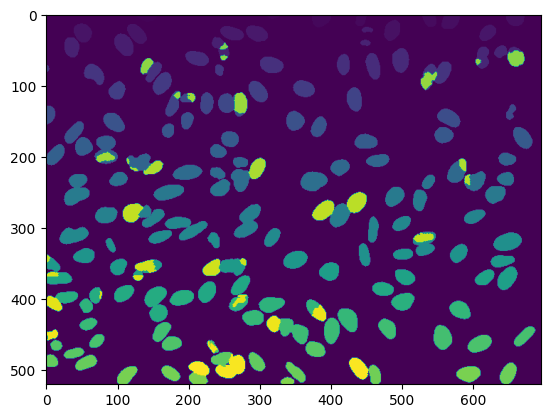

In [2]:
import numpy as np
import matplotlib.pyplot as plt

mask = np.load('/data5/zhangye/FCIS/z_dsb_zy/4dbbb275960ab9e4ec2c66c8d3000f7c70c8dce5112df591b95db84e25efa6e9.npy')
plt.imshow(mask)
plt.show()